Title: Scraping 101\
Summary: webscraping, beautiful soup library, social listening, web structure\
main references:\
Scope: Data Science for Public Policy Course\
Last update: 2025-03-18\
Author: Arnaud Weiss\
Revision: Silvia Tulli


# **Scraping 101**
**Table of Contents**
* How does the internet work?
  * HTTP and the internet
  * Introduction to HTML

* Scraping 101
  * Scraping a static webpage
  * Scraping a dynamic page
  * Challenge
  * Advanced scraping - Selenium & social networks

# How does the internet work?

## HTTP, clients & servers
To perform scraping, it's useful to get a grasp of how the internet works.

The internet is made of computers connected to the web. If we simplify, there are of two types: clients and servers.  Servers store data such as websites or apps. Clients - like your computer or your smartphone - download the aforementioned data from the servers. HTTP is the language for clients and servers to speak to each other.

Question: what is the term for client to client communication? (hint: did you ever use Bittorrent?)

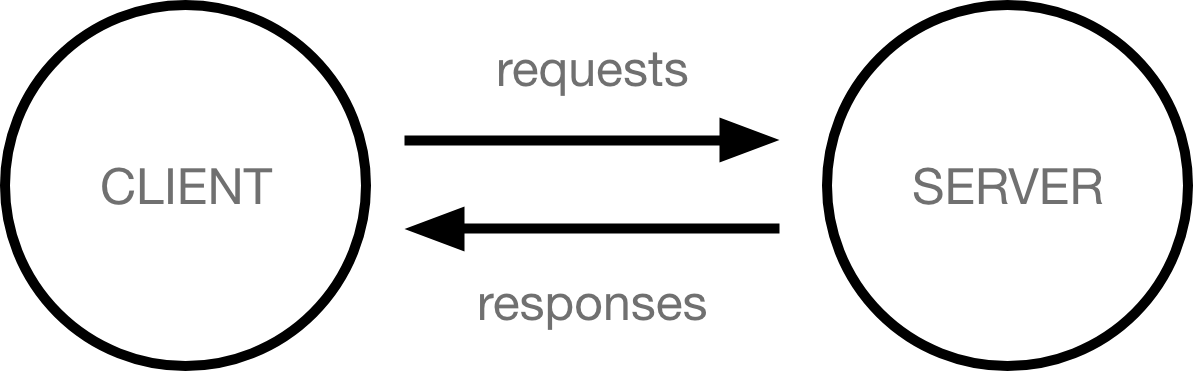

When you log an URL or click on a link, the browser sends an HTTP **"Get"** request message to the server. You basically ask it to send you (the client) a copy of the website. If the server approves the client's request, it shares with you the website's files in the form of an HTML file. It would look something like this:



```
<!DOCTYPE html>
<html>
<head>
<title>Sciences Po Homepage</title>
</head>
<body>

<h1>WELCOME TO SCPO WEBSITE HOMEPAGE</h1>
<p>
<a href="/usages-numeriques/fr/">Usages Numériques</a>
</p>
<p>Lorem ipsum et doloret.</p>

</body>
</html>


```

But that's not a very convenient way to look at information. Therefore, your browser parses the HTML, does a bunch of stuff with CSS & JS that we won't cover today and **builds a visual representation of the page**. You can see the HTML code and interact with it if you right click on a webpage and choose "inspect".


To learn more, have a look at [this resource](https://web.stanford.edu/class/msande91si/www-spr04/readings/week1/InternetWhitepaper.htm#:~:text=The%20web%20browser%20connects%20to,an%20HTTP%20404%20error%20message.) from Stanford. You can also check this brief history of internet [on this link](https://www.explainthatstuff.com/internet.html).


## Introduction to HTML

HTML (HyperText Markup Language) is the standard markup language for creating Web pages. It tells your browser how to structure the web pages you visit. HTML consists of a series of **elements** that tell the browser what to display and how to style it. HTML **elements** label pieces of content such as "this is a heading", "this is a paragraph", "this is a link", etc.

```
<h1>WELCOME TO SCPO WEBSITE HOMEPAGE</h1>
<p>
Do not expect too many power plugs in classrooms
</p>
```
For instance, < h1 > above tells us that the text "Welcome to ..." is a title and should be displayed as such. < p > means this is a paragraph of text.




### Anatomy of an HTML element
An element is a piece of a webpage. It may contain a data item or a chunk of text or an image, or perhaps nothing.
A typical element includes
*   **an opening tag**
*   some **attributes**
*   enclosed **text content**
*   a **closing tag**.
[More](https://developer.mozilla.org/en-US/docs/Glossary/Element)

This knowledge of the structure of an element will allow us to scrape information from webpages.

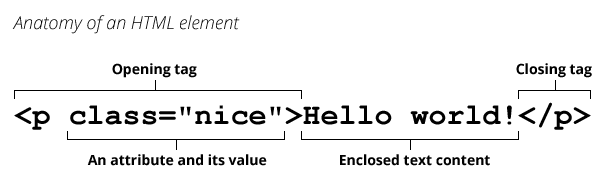


Let's have a look at our previous example:
```
<!DOCTYPE html>
<html>
<head>
<title>Sciences Po Homepage</title>
</head>

<body>

<h1>WELCOME TO SCPO WEBSITE HOMEPAGE</h1>
	<p>
	<a href="/usages-numeriques/fr/">Usages Numériques</a>
	</p>
	</div>
	<p>Lorem ipsum et doloret.</p>

</body>
</html>


```

We only care about what's inside the "body" tags as the rest is not displayed on the webpage. Here are the main types of elements in HTML. You don't need to know them all, as you can hover over anything on a webpage to discover what they are in HTML.


*   **h** is a title and **p** a paragraph
*   **Div** is a section or container - basically a box to structure content
*   **a** tag defines a hyperlink. The href attribute specifies the URL of the page the link goes to

```
<a href="https://www.sciencespo.fr/en/">Visit SciencesPo</a>

```
*   **img** is an image. The src attribute specifies the path to the image to be displayed. Note that this is a void element without a closing tag.

```
<img src="img_girl.jpg">
```


etc.


You can find a complete list of tags and their use [on this link](https://www.w3schools.com/tags/default.asp).

###Attributes of elements

The attributes of the element contain **extra information about the element that won't appear in the content**.

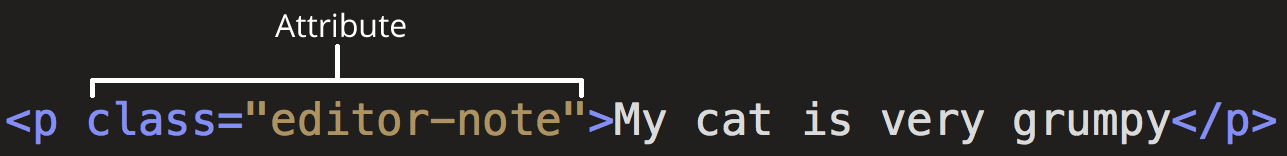
In this example, the class attribute is an identifying name used to target the element with style information.

Attributes are important because they allow us to

1.   Identify similar pieces of content and
2.   Retrieve some information e.g. an URL in the case of an hyperlink, an image etc.

A couple of very common attributes you should be familiar with:
*   **id**: Identifies a unique element within the HTML document. IDs should be unique within a page.
*   **class**: a group of visual attributes applied to several pieces of the website.
*   **Href** - hyperlink
*   **src** specifies the path to the image to be displayed
*   **alt** provides a text description of the image (very useful for scrapping)

Please bear in mind that an element can carry several attributes, separated with whitespaces.


```
<a href="https://www.example.com" title="Visit Example Website">Click here</a>
```

In the example below, the < a > element has two attributes:
1. `href` specifies the URL to which the link leads
2. `title` provides additional information about the link when a user hovers over it with their mouse



### To learn more about HTML

In-depth knowledge of HTML is not required for scraping. If you want to learn more about the language, you can check these tutorials

*   [Web3s school HTML intro](https://www.w3schools.com/html/default.asp)
*   [Mozilla course on HTML](https://developer.mozilla.org/en-US/docs/Web/HTML)



####Exercise 2

Go to [this HTML editor](https://www.w3schools.com/html/tryit.asp?filename=tryhtml_intro). Play with the HTML to
1. Change the title and the paragraph content
2. Add a hyperlink leading to SciencesPo homepage, with additional information if you hover it
3. Add an image of a cute dog or cat



# Introduction to scraping

## Scraping a static page

To scrape data, we will mainly use the following libraries

*   `requests` allows you to send HTTP/1.1 requests and mimic the behaviour of your browser [Learn more](https://pypi.org/project/requests/)
*   `BeautifulSoup` contains methods to scrape information from web pages. [Learn more](https://pypi.org/project/beautifulsoup4/)





Okay let's start with an easy one. We will scrape the content of a news article. Let's take [this one](https://www.theguardian.com/science/2024/apr/12/bonobos-not-the-peace-loving-primates-once-thought-study-reveals) from The Guardian.

In [1]:
import requests  # HTTP requests module
from bs4 import BeautifulSoup  # HTML reading /scraping module

webpage = requests.get("https://www.theguardian.com/science/2024/apr/12/bonobos-not-the-peace-loving-primates-once-thought-study-reveals")
# We send a get HTTP request to fetch the webpage and pass it to an object.

print(webpage.status_code)  # The webpage object comes with distinct methods, such as status code,
# which tells you if connection was successful: 404 means no. 200 yes


ModuleNotFoundError: No module named 'requests'

In [ ]:
soup = BeautifulSoup(webpage.content, 'html.parser')  # We then read the html (which is put as a string in
# webpage.content) with BeautifulSoup, and assign it to a variable we call "soup"

print(soup)
#Let's have a look at our HTML.

<!DOCTYPE html>

<html lang="en">
<head>
<!-- Hello there, HTML enthusiast! -->
<!-- DCR commit hash 39bce09cb3c83cb35ef597529da44d350d3c5921 -->
<title>Bonobos not the peace-loving primates once thought, study reveals | Animal behaviour | The Guardian</title>
<meta content="Male-on-male aggression more frequent among bonobos than chimps, but aggression between males and females less common" name="description"/>
<meta charset="utf-8"/>
<link href="https://www.theguardian.com/science/2024/apr/12/bonobos-not-the-peace-loving-primates-once-thought-study-reveals" rel="canonical"/>
<meta content="width=device-width,minimum-scale=1,initial-scale=1" name="viewport"/>
<meta content="#052962" name="theme-color">
<link href="https://assets.guim.co.uk/static/frontend/manifest.json" rel="manifest"/>
<link href="https://assets.guim.co.uk/static/frontend/icons/homescreen/apple-touch-icon.svg" rel="apple-touch-icon" sizes="any"/>
<link href="https://assets.guim.co.uk/static/frontend/icons/homescreen/

In [ ]:
#Now let's use the method .find to extract the title of the article
title = soup.find(class_="dcr-u0152o")  # Using that soup object,
# we look for an element whose class (the html attribute) matches the one we are looking for

print(title)

<h1 class="dcr-u0152o">Bonobos not the peace-loving primates once thought, study reveals</h1>


In [ ]:
content = title.text  # Next, we can use this element to get the piece
# we are actually interested in, which is the text
print(content)

Bonobos not the peace-loving primates once thought, study reveals


In [ ]:
#You don't need all these intermediary steps that I added for clarity purposes.
#One line of code is enough
content = soup.find(class_="dcr-u0152o").text
print(content)

Bonobos not the peace-loving primates once thought, study reveals


###Exercise 3

Extract from the same web page the text content of the first paragraph of the article. Print it without the HTML tags.

In [ ]:
import requests
from bs4 import BeautifulSoup
url = "https://www.theguardian.com/science/2024/apr/12/bonobos-not-the-peace-loving-primates-once-thought-study-reveals"

# Télécharger la page
response = requests.get(url)

if response.status_code == 200:
    soup = BeautifulSoup(response.text, "html.parser")

    # Chercher le premier paragraphe
    first_paragraph = soup.find("p")

    if first_paragraph:
        print(first_paragraph.text)
    else:
        print("Aucun paragraphe trouvé.")
else:
    print("Erreur de téléchargement.")

Male-on-male aggression more frequent among bonobos than chimps, but aggression between males and females less common


##More useful scraping commands

In [ ]:
#A very common operation in scraping: fetching all the text of a page
#(that's basically what OpenAI did to train ChatGPT on the NYT for instance)
content_art = soup.get_text()
print(content_art)






Bonobos not the peace-loving primates once thought, study reveals | Animal behaviour | The Guardian




























































































Skip to main contentSkip to navigationClose dialogue1/1Next imagePrevious imageToggle captionSkip to navigationPrint subscriptionsNewsletters Sign inUSUS editionUK editionAustralia editionEurope editionInternational editionThe Guardian - Back to homeThe GuardianNewsOpinionSportCultureLifestyleShow moreHide expanded menuNewsView all NewsUS newsUS politicsWorld newsClimate crisisMiddle EastUkraineSoccerBusinessEnvironmentTechScienceNewslettersWellnessOpinionView all OpinionThe Guardian viewColumnistsLettersOpinion videosCartoonsSportView all SportSoccerNFLTennisMLBMLSNBAWNBANHLF1GolfCultureView all CultureFilmBooksMusicArt & designTV & radioStageClassicalGamesLifestyleView all LifestyleWellnessFashionFoodRecipesLove & sexHome & gardenHealth & fitnessFamilyTravelMoneySearch input google-search S

In [ ]:
#There is a lot of blank space, let's remove it
#The strip() method removes any starting and ending whitespaces from a string
content_art = soup.get_text(strip = True)
print(content_art)

Bonobos not the peace-loving primates once thought, study reveals | Animal behaviour | The GuardianSkip to main contentSkip to navigationClose dialogue1/1Next imagePrevious imageToggle captionSkip to navigationPrint subscriptionsNewslettersSign inUSUS editionUK editionAustralia editionEurope editionInternational editionThe Guardian - Back to homeThe GuardianNewsOpinionSportCultureLifestyleShow moreHide expanded menuNewsView all NewsUS newsUS politicsWorld newsClimate crisisMiddle EastUkraineSoccerBusinessEnvironmentTechScienceNewslettersWellnessOpinionView all OpinionThe Guardian viewColumnistsLettersOpinion videosCartoonsSportView all SportSoccerNFLTennisMLBMLSNBAWNBANHLF1GolfCultureView all CultureFilmBooksMusicArt & designTV & radioStageClassicalGamesLifestyleView all LifestyleWellnessFashionFoodRecipesLove & sexHome & gardenHealth & fitnessFamilyTravelMoneySearch inputgoogle-searchSearchSupport usPrint subscriptionsNewslettersDownload the appSearch jobsDigital ArchiveGuardian Licen

In [ ]:
# Another common operation in web scraping: extracting all elements of a certain type
# For example, extracting all images from a webpage or all hyperlinks (links).
# In this case, we will extract all hyperlinks.

# Initialize an empty list to store the extracted links
LinksDB = []

# Loop through all <a> (anchor) elements in the parsed HTML document
for link in soup.find_all('a'):
    # Extract the hyperlink reference (href attribute) from each <a> tag
    LinksDB.append(link.get('href'))

# Print the list of extracted hyperlinks
print(LinksDB)


['#maincontent', '#navigation', '#navigation', 'https://support.theguardian.com/subscribe/weekly?REFPVID=undefined&INTCMP=undefined&acquisitionData=%7B%22source%22%3A%22GUARDIAN_WEB%22%2C%22componentId%22%3A%22PrintSubscriptionsHeaderLink%22%2C%22componentType%22%3A%22ACQUISITIONS_HEADER%22%2C%22referrerUrl%22%3A%22%22%7D', '/email-newsletters', 'https://profile.theguardian.com/signin?INTCMP=DOTCOM_NEWHEADER_SIGNIN&ABCMP=ab-sign-in&componentEventParams=componentType%3Didentityauthentication%26componentId%3Dguardian_signin_header', '/preference/edition/us', '/preference/edition/uk', '/preference/edition/au', '/preference/edition/eur', '/preference/edition/int', '/', '/', '/commentisfree', '/sport', '/culture', '/lifeandstyle', '/', '/us-news', '/us-news/us-politics', '/world', '/environment/climate-crisis', '/world/middleeast', '/world/ukraine', '/us/soccer', '/us/business', '/us/environment', '/us/technology', '/science', '/email-newsletters', '/us/wellness', '/commentisfree', '/profil

In [ ]:
# I don't want all the hyperlinks from the drop-down menu or other parts of the page.
# I'll restrict my scraping to only the main content of the article.

# Initialize an empty list to store extracted hyperlinks
LinksDB = []

# Locate the main content area
main_content = soup.find("div", {"data-gu-name": "body"})  # Adjust based on inspection

# Initialize a list to store the hyperlinks
LinksDB = []

# Check if the main content section exists
if main_content:
    # Find all anchor tags <a> inside the article content
    for link in main_content.find_all("a"):
        href = link.get("href")  # Extract the href attribute
        if href:  # Ensure the href is not None
            LinksDB.append(href)

# Print the extracted hyperlinks
print(LinksDB)

['https://www.cell.com/current-biology/fulltext/S0960-9822(24)00253-7', '/science/animalbehaviour', '/science/primatology', '/science/biology', '/world/animals', '/tone/news', 'mailto:?subject=Bonobos not the peace-loving primates once thought, study reveals&body=https://www.theguardian.com/science/2024/apr/12/bonobos-not-the-peace-loving-primates-once-thought-study-reveals?CMP=share_btn_url', 'https://syndication.theguardian.com/?url=https%3A%2F%2Fwww.theguardian.com%2Fscience%2F2024%2Fapr%2F12%2Fbonobos-not-the-peace-loving-primates-once-thought-study-reveals&type=article&internalpagecode=science/2024/apr/12/bonobos-not-the-peace-loving-primates-once-thought-study-reveals']


In your scraping journey, you'll also need the following commands

*   soup.parent() finds the parent tag (the tag that wraps the current element)
*   soup.children() finds all direct child elements inside a tag. Returns an iterator, so you need to loop through it.


Learn more [in the documentation](https://www.crummy.com/software/BeautifulSoup/bs4/doc/)


In [ ]:
liste = ["bateau", "avion", "rouge"]
for mot in liste:
  print(mot)

bateau
avion
rouge


In [ ]:
#Example 1
html = """
<div>
    <p>This is inside a div.</p>
</div>
"""

soup = BeautifulSoup(html, "html.parser")

# Find the <p> tag
p_tag = soup.find("p")
print("Paragraph:", p_tag)

# Get the parent of <p> (which is <div>)
parent_div = p_tag.parent
print("Parent:", parent_div)


Paragraph: <p>This is inside a div.</p>
Parent: <div>
<p>This is inside a div.</p>
</div>


In [ ]:
# Declare variables of basic data types
my_integer = 42
my_float = 3.14
my_string = "Hello, world!"
my_boolean = True

# Print the type of each variable
print("Type of my_integer:", type(my_integer))
print("Type of my_float:", type(my_float))
print("Type of my_string:", type(my_string))
print("Type of my_boolean:", type(my_boolean))


In [ ]:
#Example 2
html = """
<div>
    <p>First child paragraph.</p>
    <p>Second child paragraph.</p>
</div>
"""

soup = BeautifulSoup(html, "html.parser")

# Find the <div> tag
div_tag = soup.find("div")

# Get all direct children of <div>
children = list(div_tag.children)

# Print each child
for i, child in enumerate(children, 1):
    print(f"Child {i}:", child)

#Note that it returns white space as well

Child 1: <p>First child paragraph.</p>
Child 2: <p>Second child paragraph.</p>


##Scraping challenge!

###**Challenge #1**

1. Store [this article](https://www.theguardian.com/lifeandstyle/2024/apr/13/white-spirit-creating-a-minimalist-home-in-london) in a soup
2. Store and print all the text in a variable

###**Challenge #2**

1. Extract all the headings (h2 tags) from this [Wikipedia page.](https://en.wikipedia.org/wiki/Capybara) using find_all() and store them in a list.
2. Print the first five elements of this list

###**Challenge #3**

1. Scrape all hyperlinks from the page https://www.bbc.com/news using find_all()
2. Bonus: filter out only external links (that start with "http").

###**Challenge #4**
1. Scrape country population data from Wikipedia tables of this article url = "https://en.wikipedia.org/wiki/List_of_countries_by_population_(United_Nations)"
2. Store it in a dataframe

Tips: you will need the following pieces of code

```
# Find the first table with class "wikitable"
table = soup.find("table", class_="wikitable")

# Extract rows
rows = table.find_all("tr")
```

###**Challenge #5**


You fill focus on the [French Constitution](https://www.conseil-constitutionnel.fr/le-bloc-de-constitutionnalite/texte-integral-de-la-constitution-du-4-octobre-1958-en-vigueur).

1. Store in a variable and print the second article of the constitution
2. The Constitution is divided in parts and sub-sections. The subsections, if you look at the code-source, are  found in elements whose tag is "h2". Write an algorithm that returns the section with the most articles (subarticles of the form "56-X" count as one). There are several ways to go about it.

###**Challenge #6**

This is for the most experienced of you. Note that you might need Selenium.

[This page](https://www.bailii.org/cgi-bin/lucy_search_1.cgi?highlight=1&show=20&query=Arbitration+Gold+Venezuela&sort=date) contains a list of the 20 most recent decisions from the UK courts with some keywords

Extract all URLS to the judgments viewed as "Without Highlighting", put them in a list urls
Then visit each url in turn, and:

Extract the citation number(s)
Extract the name of the judge
Extract the date of hearing
Extract the number of paragraphs
Put all that data in a dataframe (use the list of list methods: each judgment's data in one list, each list in a bigger list which you'll pass to pd.Dataframe())


‘The negative white space encourages a wonderful interplay of light and shadow’: the ethereal kitchen.
Photograph: Chris Everard
View image in fullscreen
‘The negative white space encourages a wonderful interplay of light and shadow’: the ethereal kitchen.
Photograph: Chris Everard
The Observer
Interiors
This article is more than
10 months old
White spirit: creating a minimalist home in London
This article is more than 10 months old
Restraint and calm are the guiding lights in this stunningly sparse apartment
Chrissie Rucker
Sat 13 Apr 2024 15.00 CEST
Last modified on Thu 6 Mar 2025 15.05 CET
Share
F
or couturier
Anna Valentine
, there is an overwhelming similarity between the principles behind her studio and the way she has designed her London apartment. Yet it is the sense of atmosphere at the core of this home’s refined DNA that leaves the strongest imprint. It is a graceful space, without pretence, where less is definitely more.
The first-floor Georgian apartment, which Anna shares

##Scraping dynamic pages

Many pages are dynamic, which means that some content can be accessed only through interaction with some elements (e.g. a button).

Think about a Google search for instance. To see all the results of your research, you would need to click on the button "next page" many times.

In that case, we need to innovate a little bit. Let's start with a simple example: I want to retrieve the table with all climate tech unicorns from [this page](https://www.holoniq.com/climatetech-unicorns).

In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
from dataclasses import dataclass

# Define a data class `ClimateTechUnicorn` using the `@dataclass` decorator
# The @dataclass decorator is used to automatically generate special
# methods like _init_, _repr_, and _eq_ among others for the class,
# simplifying the process of creating classes for storing data.
@dataclass
class ClimateTechUnicorn:
  name: str
  valuation: str
  sector: str

  # Define a method to convert the object to a dictionary
  def as_dict(self) -> dict[str, str]:
    return {
        "name": self.name,
        "valuation": self.valuation,
        "sector": self.sector
    }

# Define a function to scrape data
def scrape() -> list[ClimateTechUnicorn]:

  i = 1  # Initialize a counter for pagination
  parsed_items = []  # Initialize an empty list to store parsed items

  # Loop indefinitely until there are no more items to scrape
  while True:
    # Construct the URL with pagination
    url = f"https://www.holoniq.com/climatetech-unicorns?71d317c6_page={i}"

    # Get the HTML content of the webpage
    parsed_html = BeautifulSoup(requests.get(url).text)

    # Find the container element for the list of items
    table = parsed_html.find("div", class_="w-dyn-list")

    # Find all items within the container
    items = table.find_all("div", role="listitem")

    # If no items are found, exit the loop
    if not items:
      return parsed_items

    # Iterate over each item and extract relevant information
    for row in items:
      name = row.find("div", class_="company-name").string
      valuation = row.find("div", class_="text-block-7").string
      cluster = row.find("div", class_="text-block-3").string

      # Create a ClimateTechUnicorn object and append it to the list
      parsed_items.append(ClimateTechUnicorn(
          name=name,
          valuation=valuation,
          sector=cluster))

    # Increment the counter for pagination
    i += 1

# Convert the list of objects to a DataFrame and print it
df = pd.DataFrame([item.as_dict() for item in scrape()])
print(df)


                               name valuation                  sector
0                            Cruise    $14.6B           Road Vehicles
1    GAC Aion New Energy Automobile    $14.2B           Road Vehicles
2                          GoodLeap    $12.0B            Solar Energy
3                         Northvolt    $11.8B  Battery Energy Storage
4      Mahindra Electric Automobile     $9.8B           Road Vehicles
..                              ...       ...                     ...
114                     SKIO Matrix     $1.0B           Road Vehicles
115                        PowerOak     $1.0B  Battery Energy Storage
116                         EcoFlow     $1.0B            Solar Energy
117             Jiangsu Horizon New     $1.0B  Battery Energy Storage
118                          Semios     $1.0B                   Crops

[119 rows x 3 columns]


##Advanced scraping - social networks etc

Now that you understand the basics, you can explore more advanced scraping tasks.

1. To handle complex dynamic pages, the library `Selenium` allows you to mimic the behaviour of a human on a webpage to extract information. It's critical for advanced scraping

-> [Guide on how to use it in Colab](https://www.geeksforgeeks.org/how-to-do-web-scraping-using-selenium-and-google-colab/)

2. Social listening, mining social networks

SciencesPo researchers developed a library called `Minet` dedicated to scraping for social sciences. You can use it to scrape Facebook, CrowdTangle, YouTube, Twitter, Media Cloud ...

-> [Link](https://github.com/medialab/minet?tab=readme-ov-file#installation)

Scraping comes with the following challenges
*   Not getting caugh (e.g. Linkedin)
*   Extract massive amount of data in a short timespan, with limited resources
*   Maintain your scraper - adapt it to webpages evolutions
*   Handle errors in a smart way - don't start from scratch at the smallest bump

# Solutions to the exercises

These are reference solutions. Web pages change over time, so selectors and page structure may need small adjustments. The scraping examples include timeouts, status checks, and polite request headers where appropriate.

## Exercise 2 — Edit the HTML

Paste this into the W3Schools HTML editor. The `title` changes the browser-tab title; the `title` attribute on the link provides hover text.

In [ ]:
<!DOCTYPE html>
<html>
<head>
  <title>My HTML Practice Page</title>
</head>
<body>
  <h1>Welcome to my page!</h1>
  <p>I am learning HTML and web scraping.</p>

  <p>
    Visit the
    <a href="https://www.sciencespo.fr/"
       title="Open the Sciences Po homepage">
      Sciences Po homepage
    </a>.
  </p>

  <img
    src="https://images.dog.ceo/breeds/retriever-golden/n02099601_100.jpg"
    alt="A cute golden retriever"
    width="300">
</body>
</html>

## Exercise 3 — Extract the first article paragraph

Rather than selecting the first `<p>` on the entire page (which might be a navigation or accessibility paragraph), first try to locate the article body. The fallback keeps the example useful if the site's CSS classes change.

In [ ]:
import requests
from bs4 import BeautifulSoup

url = "https://www.theguardian.com/science/2024/apr/12/bonobos-not-the-peace-loving-primates-once-thought-study-reveals"
response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0 (educational scraping example)"},
    timeout=20,
)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")

article = soup.find("div", {"data-gu-name": "body"}) or soup.find("article")
first_paragraph = article.find("p") if article else soup.find("p")

if first_paragraph:
    print(first_paragraph.get_text(" ", strip=True))
else:
    print("No paragraph was found; the page structure may have changed.")

## Scraping challenge — Challenge 1

Download the article, parse it into a BeautifulSoup object, and store all page text in a variable.

In [ ]:
import requests
from bs4 import BeautifulSoup

url = "https://www.theguardian.com/lifeandstyle/2024/apr/13/white-spirit-creating-a-minimalist-home-in-london"
response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0 (educational scraping example)"},
    timeout=20,
)
response.raise_for_status()

soup = BeautifulSoup(response.text, "html.parser")
all_text = soup.get_text(separator=" ", strip=True)
print(all_text)

## Challenge 2 — Wikipedia headings

Use `find_all("h2")`, convert the headings to plain text, and print the first five.

In [ ]:
import requests
from bs4 import BeautifulSoup

url = "https://en.wikipedia.org/wiki/Capybara"
response = requests.get(
    url,
    headers={"User-Agent": "EducationalScraper/1.0 (learning exercise)"},
    timeout=20,
)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")

headings = [
    heading.get_text(" ", strip=True)
    for heading in soup.find_all("h2")
]
print(headings[:5])

## Challenge 3 — Extract hyperlinks

The first list contains every anchor's `href` value (excluding anchors without an `href`). The second keeps absolute URLs that begin with `http`, as requested in the bonus.

In [ ]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin

url = "https://www.bbc.com/news"
response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0 (educational scraping example)"},
    timeout=20,
)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")

links = [
    anchor["href"]
    for anchor in soup.find_all("a", href=True)
]
external_links = [link for link in links if link.startswith("http")]

print("All href values:", links)
print("Absolute HTTP(S) links:", external_links)

# Optional improvement: turn relative links into absolute URLs before filtering.
absolute_links = [urljoin(url, link) for link in links]
print("Absolute URLs (including resolved relative links):", absolute_links)

## Challenge 4 — Country population table to a DataFrame

Wikipedia may reorder or rename columns. This solution reads the first `wikitable`, uses its header row for column names, and skips rows that do not match the header width.

In [ ]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

url = "https://en.wikipedia.org/wiki/List_of_countries_by_population_(United_Nations)"
response = requests.get(
    url,
    headers={"User-Agent": "EducationalScraper/1.0 (learning exercise)"},
    timeout=20,
)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")

table = soup.find("table", class_="wikitable")
if table is None:
    raise ValueError("Could not find a wikitable; Wikipedia's page structure may have changed.")

rows = table.find_all("tr")
header_row = rows[0]
headers = [
    cell.get_text(" ", strip=True)
    for cell in header_row.find_all(["th", "td"])
]

records = []
for row in rows[1:]:
    cells = row.find_all(["th", "td"])
    values = [cell.get_text(" ", strip=True) for cell in cells]
    if len(values) == len(headers):
        records.append(values)

population_df = pd.DataFrame(records, columns=headers)
display(population_df.head())
print(population_df.shape)

## Challenge 5 — French Constitution

The page structure can change, so inspect the selected elements if the output is empty. The first code cell tries to identify Article 2 by its heading. The second walks through each `h2` section and counts distinct article numbers, treating subarticles such as `56-1` as the same base article `56`.

In [ ]:
import requests
from bs4 import BeautifulSoup
import re

url = "https://www.conseil-constitutionnel.fr/le-bloc-de-constitutionnalite/texte-integral-de-la-constitution-du-4-octobre-1958-en-vigueur"
response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0 (educational scraping example)"},
    timeout=20,
)
response.raise_for_status()
soup = BeautifulSoup(response.text, "html.parser")

# Find a heading or element whose text begins with "Article 2".
article2 = None
for element in soup.find_all(["h2", "h3", "h4", "p", "strong", "div"]):
    text = element.get_text(" ", strip=True)
    if re.match(r"^Article\s*2\b", text, flags=re.IGNORECASE):
        article2 = element
        break

if article2:
    print(article2.get_text(" ", strip=True))
    # Print following content until the next article heading, where possible.
    parts = []
    for sibling in article2.find_all_next():
        if sibling.name in {"h2", "h3", "h4"} and re.match(
            r"^Article\s*\d+", sibling.get_text(" ", strip=True), re.I
        ):
            break
        if sibling.name in {"p", "li"}:
            text = sibling.get_text(" ", strip=True)
            if text:
                parts.append(text)
    print("\n".join(parts))
else:
    print("Article 2 was not identified. Inspect soup headings and page structure.")

In [ ]:
# Count distinct base article numbers within each h2 section.
# Subarticles such as 56-1 and 56-2 count as article 56.
section_counts = []
current_section = "Content before the first h2"
current_articles = set()

def save_section(name, article_numbers):
    if name and article_numbers:
        section_counts.append({
            "section": name,
            "number_of_articles": len(article_numbers),
            "article_numbers": sorted(article_numbers, key=lambda x: int(x)),
        })

for element in soup.find_all(["h2", "h3", "h4", "p", "li", "div"]):
    if element.name == "h2":
        save_section(current_section, current_articles)
        current_section = element.get_text(" ", strip=True)
        current_articles = set()
        continue

    text = element.get_text(" ", strip=True)
    # Only count labels that explicitly start with "Article <number>".
    match = re.match(r"^Article\s+(\d+)(?:-\d+)?\b", text, flags=re.IGNORECASE)
    if match:
        current_articles.add(match.group(1))

save_section(current_section, current_articles)

if section_counts:
    section_counts.sort(key=lambda item: item["number_of_articles"], reverse=True)
    print("Section with the most articles:")
    print(section_counts[0]["section"])
    print("Distinct articles:", section_counts[0]["number_of_articles"])
    print("Article numbers:", section_counts[0]["article_numbers"])
else:
    print("No article labels were detected. Inspect the HTML and adjust the matching rule.")

## Challenge 6 — BAILII judgments

This is a best-effort template: BAILII's HTML and access policies may change. It extracts links labelled “Without Highlighting”, then visits each judgment and looks for common metadata labels. Always check the resulting DataFrame manually because judge/date/citation formats differ across judgments.

In [ ]:
import re
import time
import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin

search_url = (
    "https://www.bailii.org/cgi-bin/lucy_search_1.cgi"
    "?highlight=1&show=20&query=Arbitration+Gold+Venezuela&sort=date"
)
headers = {"User-Agent": "Mozilla/5.0 (educational research scraper)"}
session = requests.Session()
session.headers.update(headers)

response = session.get(search_url, timeout=25)
response.raise_for_status()
search_soup = BeautifulSoup(response.text, "html.parser")

urls = []
for anchor in search_soup.find_all("a", href=True):
    label = anchor.get_text(" ", strip=True).lower()
    if "without highlighting" in label:
        urls.append(urljoin(search_url, anchor["href"]))

# Remove duplicate URLs while preserving order.
urls = list(dict.fromkeys(urls))
print(f"Found {len(urls)} judgment URLs")
print(urls)

In [ ]:
def extract_judgment_metadata(url, session=session):
    response = session.get(url, timeout=25)
    response.raise_for_status()
    soup = BeautifulSoup(response.text, "html.parser")
    text = soup.get_text("\n", strip=True)

    # Citation formats vary; collect likely neutral/official citations.
    citations = re.findall(
        r"\b(?:\[\d{4}\]\s*[A-Z]{2,}[A-Za-z0-9.()/-]*\s*\d+"
        r"|\(\d{4}\)\s*[^\n]{0,80}?\s\d+"
        r"|\[\d{4}\]\s*UK[A-Z]{2,}\s*\d+)\b",
        text,
    )

    # Search nearby text for common judge and hearing-date labels.
    judge = None
    date_of_hearing = None
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    for i, line in enumerate(lines):
        lower = line.lower()
        if judge is None and any(term in lower for term in ("before:", "before ", "judge:", "judgment of")):
            judge = line[:250]
        if date_of_hearing is None and any(term in lower for term in ("date of hearing", "hearing date", "heard on")):
            date_of_hearing = line[:250]

    # Count numbered paragraphs like [1], [2] or (1), (2), without assuming all judgments use them.
    paragraph_numbers = re.findall(r"(?m)^\s*\[(\d{1,4})\]\s+", text)
    if paragraph_numbers:
        paragraph_count = len(set(paragraph_numbers))
    else:
        paragraph_count = None

    return {
        "url": url,
        "citations": "; ".join(dict.fromkeys(citations)) or None,
        "judge": judge,
        "date_of_hearing": date_of_hearing,
        "number_of_paragraphs": paragraph_count,
    }

results = []
for url in urls:
    try:
        results.append(extract_judgment_metadata(url))
    except requests.RequestException as exc:
        results.append({
            "url": url,
            "citations": None,
            "judge": None,
            "date_of_hearing": None,
            "number_of_paragraphs": None,
            "error": str(exc),
        })
    time.sleep(1)  # Be considerate to the host.

judgments_df = pd.DataFrame(results)
display(judgments_df)
# If the page uses different labels, inspect one judgment's text and adapt the patterns.

## Notes on the dynamic-page example

The original HolonIQ example is a demonstration of pagination, but the site may change its markup or restrict automated requests. A safer version below checks HTTP status, handles a missing container, and stops if a page has no list items. If the site changes, inspect `parsed_html` and update the CSS classes.

In [ ]:
# Robust pattern for a paginated page (adapt selectors if the site markup changes).
from dataclasses import dataclass
import requests
import pandas as pd
from bs4 import BeautifulSoup

@dataclass
class ClimateTechUnicorn:
    name: str
    valuation: str
    sector: str

    def as_dict(self):
        return {"name": self.name, "valuation": self.valuation, "sector": self.sector}

def scrape(max_pages=20):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0 (educational scraping example)"})
    parsed_items = []

    for page in range(1, max_pages + 1):
        url = f"https://www.holoniq.com/climatetech-unicorns?71d317c6_page={page}"
        response = session.get(url, timeout=20)
        response.raise_for_status()
        soup = BeautifulSoup(response.text, "html.parser")
        container = soup.find("div", class_="w-dyn-list")
        if container is None:
            break

        items = container.find_all("div", role="listitem")
        if not items:
            break

        for item in items:
            def field(class_name):
                node = item.find("div", class_=class_name)
                return node.get_text(" ", strip=True) if node else ""

            name = field("company-name")
            valuation = field("text-block-7")
            sector = field("text-block-3")
            if name:
                parsed_items.append(ClimateTechUnicorn(name, valuation, sector))

    return parsed_items

# Uncomment to run; the website may have changed since this lesson was written.
# unicorns_df = pd.DataFrame([item.as_dict() for item in scrape()])
# display(unicorns_df.head())